# How the range model learns — a walkthrough you take part in

This notebook rebuilds Windrose's range model step by step: the data, the baselines it must beat, the
physics behind it, how it borrows the car's specifications while data is scarce, where it goes wrong and how
sure it is. Along the way there are **Your turn** cells: decisions an ML engineer makes, made by you, with
the consequences shown straight after.

It runs on generated **demo data** by default, so it works for anyone who clones the repository and the
outputs saved in it contain nothing personal.

> **Using your own drives.** Save a copy as `model_walkthrough.local.ipynb` (git ignores `*.local.ipynb`),
> put a copy of your database at `data/kiatracker.duckdb` (or point `KIATRACKER_NOTEBOOK_DB` at it) and set
> `PERSONAL = True` below. The notebook refuses personal data under any other file name, so real results can't
> be committed by accident.

In [1]:
import os
import tempfile
from dataclasses import replace
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kiatracker.dashboard.source import build_demo_database
from kiatracker.forecast.evaluate import backtest
from kiatracker.forecast.features import drive_features
from kiatracker.forecast.model import FEATURES, fit, fit_coefficients
from kiatracker.forecast.specs import EV3, prior_coefficients

PERSONAL = False  # True: your own database (only in a *.local.ipynb copy, see above)


def notebook_name() -> str:
    # JupyterLab and VS Code both say which file is running; unknown means "not allowed"
    return os.environ.get("JPY_SESSION_NAME") or globals().get("__vsc_ipynb_file__") or ""


if PERSONAL:
    if not notebook_name().endswith(".local.ipynb"):
        raise RuntimeError("Personal data only in a copy saved as *.local.ipynb (git ignores those).")
    db_path = Path(os.environ.get("KIATRACKER_NOTEBOOK_DB", "../data/kiatracker.duckdb"))
else:
    db_path = build_demo_database(Path(tempfile.mkdtemp()), days=120, seed=7)

con = duckdb.connect(str(db_path), read_only=True)
rows = drive_features(con)
df = pd.DataFrame(rows)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 9,
    }
)
print(f"{'Personal' if PERSONAL else 'Demo'} data: {len(df)} drives of 5 km or more with weather")

Demo data: 279 drives of 5 km or more with weather


## 1. What we predict, and from what

One row per drive. The target is **kWh per 100 km**, measured from the battery's charge before and after.
The inputs are things we know *before* a drive, so the model can be used to plan one: speed, temperature,
wind along the route and hills. GPS is used to work these out, but no coordinate leaves this step.

In [2]:
df[["distance_km", "speed_kph", "temp_c", "headwind_kph", "climb", "kwh_per_100km"]].describe().round(1)

,distance_km,speed_kph,temp_c,headwind_kph,climb,kwh_per_100km
count,279.0,279.0,279.0,279.0,279.0,279.0
mean,29.6,65.8,18.1,-0.0,294.7,15.4
std,22.4,21.6,5.9,10.8,223.9,3.9
min,5.0,25.4,1.7,-27.7,0.0,7.2
25%,17.0,50.5,14.1,-7.1,165.3,12.7
50%,25.7,64.3,19.0,0.5,238.1,15.0
75%,29.5,79.8,22.4,6.7,394.4,17.7
max,113.1,121.4,28.9,25.7,1174.4,27.3


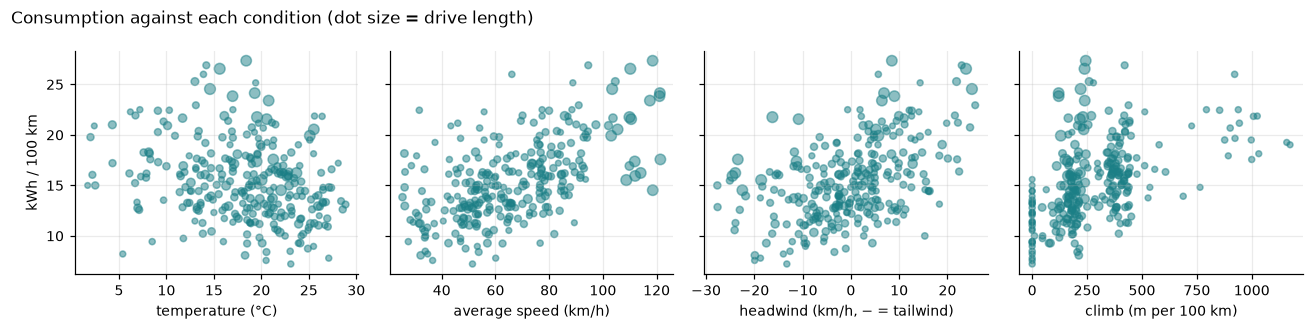

In [3]:
panels = [
    ("temp_c", "temperature (°C)"),
    ("speed_kph", "average speed (km/h)"),
    ("headwind_kph", "headwind (km/h, − = tailwind)"),
    ("climb", "climb (m per 100 km)"),
]
panels = [p for p in panels if df[p[0]].std() > 0]  # skip an input that never varies
fig, axes = plt.subplots(1, len(panels), figsize=(3 * len(panels), 3), sharey=True)
for ax, (column, label) in zip(axes, panels, strict=True):
    ax.scatter(df[column], df["kwh_per_100km"], s=12 + df["distance_km"] / 3, alpha=0.5, color="#1b7f86")
    ax.set_xlabel(label)
axes[0].set_ylabel("kWh / 100 km")
fig.suptitle("Consumption against each condition (dot size = drive length)", x=0.01, ha="left")
plt.tight_layout()

### Your turn 1 — make a prediction

Before any model: from the plots and what you know of driving this car, **which condition costs the most
energy** on a typical drive? Write it down; section 7 checks it against the fitted model.

In [4]:
MY_GUESS = "wind"  # one of: "temperature", "speed", "wind", "hills"

## 2. The bar to clear: dumb baselines and an honest test

A model is only worth its complexity if it beats simple answers. Three references:

* **mean** — always predict the average of past drives;
* **temperature only** — a straight line in temperature;
* **specs** — physics from the car's data sheet, with nothing learned from your drives.

The test is **time-ordered**: train on the earliest drives, predict the next block, add it to the training
set, repeat. Shuffling drives randomly would let the model peek at the future (the same week's weather, the
same tyre pressure) and look better than it will be in use.

In [5]:
PRIOR = prior_coefficients(EV3)
plain = backtest(rows, prior=PRIOR, strength=0.0)


def score_table(result):
    names = {
        "mean": "mean",
        "temperature_only": "temperature only",
        "specs": "specs (no learning)",
        "model": "physics model, fitted",
    }
    return pd.DataFrame({names[k]: result[k] for k in names if k in result}).T.round(2)


score_table(plain)

,mae,rmse
mean,3.17,3.98
temperature only,3.30,3.99
specs (no learning),1.50,1.92
"physics model, fitted",1.34,1.75


Errors are in kWh/100 km: **MAE** is the typical miss, **RMSE** punishes big misses more. On the demo data
the fitted model wins clearly, and the specs do badly: the demo car was simulated with a heavier base load
than the data sheet says, as a real car with winter tyres and a roof rack would be. With only a couple of
weeks of real drives the fitted model may not win yet, which is exactly why the next two sections exist.

## 3. The physics model

$$\text{kWh/100 km} = c_0 + c_\text{aero}\,(v+h)^2\,\tfrac{\rho(T)}{\rho_{15}} + c_\text{heat}\,\frac{\max(0,\,18-T)}{v}
+ c_\text{climb}\cdot\text{up} - c_\text{regen}\cdot\text{down}$$

* $c_0$ — rolling resistance, drivetrain losses and electronics: paid per km whatever the weather;
* air drag grows with the **square of airspeed** (speed $v$ plus headwind $h$), and cold air is denser;
* heating draws power **per hour**, so per km it costs more the slower you go;
* climbing lifts 1.95 t; descending gives part of it back through regenerative braking.

Every coefficient is kept **non-negative** (cold never saves energy), and each has a physical meaning, so
the car's specifications predict them before a single drive. On real drives the inputs come from each
stretch between GPS readings: its own hour's temperature, its own headwind, its own climb.

In [6]:
specs = pd.DataFrame({"from specs (prior)": PRIOR, "fitted to drives": fit_coefficients(rows)}).loc[
    ["c0", *FEATURES]
]
specs.map(lambda value: float(f"{value:.3g}"))

,from specs (prior),fitted to drives
c0,6.210000,6.52000
aero,0.000947,0.00100
heat,2.640000,11.10000
cold,0.119000,0.00000
cool,12.000000,14.10000
time,137.000000,136.00000
climb,0.005900,0.00656
regen,0.003190,0.00264


### Your turn 2 — the car's specification sheet

Some inputs are measured (mass, drag coefficient, and real-world consumption in town and on the motorway,
which fixes heating and the cold penalty); others are still guesses. The two shakiest:

* `cooling_kw_per_degree` — how many kW the air conditioning draws per °C above 24 °C (guess: 0.12);
* `regen_efficiency` — the share of a descent's energy that ends up back in the battery (guess: 0.6).

Change them and see whether the **specs-only** model predicts your drives better or worse. You are doing
by hand what the next section automates: deciding how much to trust prior knowledge.

In [7]:
MY_CAR = replace(EV3, cooling_kw_per_degree=0.12, regen_efficiency=0.6)

my_prior = prior_coefficients(MY_CAR)
mine = backtest(rows, prior=my_prior, strength=0.0)
print(f"specs-only MAE with the data-sheet guesses: {plain['specs']['mae']:.2f} kWh/100 km")
print(f"specs-only MAE with your car:               {mine['specs']['mae']:.2f} kWh/100 km")

specs-only MAE with the data-sheet guesses: 1.50 kWh/100 km
specs-only MAE with your car:               1.50 kWh/100 km


## 4. Borrowing strength from the specs

With few drives a free fit chases noise: one cold, slow, uphill trip can drag the heating coefficient
anywhere. So the fit is **pulled toward the specs**, as if we had also seen `strength` average drives that
behave exactly like the data sheet (ridge regression toward a prior). Little data: the specs dominate. Lots
of data: the drives do. The strength itself is chosen by the same time-ordered test.

best strength in the backtest: 100


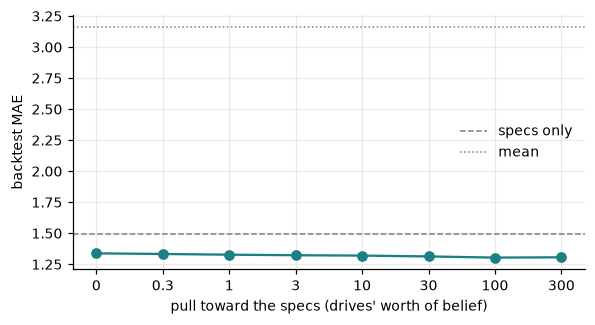

In [8]:
strengths = [0, 0.3, 1, 3, 10, 30, 100, 300]
sweep = {s: backtest(rows, prior=my_prior, strength=s)["model"]["mae"] for s in strengths}
best = min(sweep, key=sweep.get)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(len(strengths)), list(sweep.values()), marker="o", color="#1b7f86")
ax.axhline(mine["specs"]["mae"], ls="--", color="grey", lw=1, label="specs only")
ax.axhline(mine["mean"]["mae"], ls=":", color="grey", lw=1, label="mean")
ax.set_xticks(range(len(strengths)), strengths)
ax.set_xlabel("pull toward the specs (drives' worth of belief)")
ax.set_ylabel("backtest MAE")
ax.legend(frameon=False)
print(f"best strength in the backtest: {best}")

### Your turn 3 — how much do you trust the data sheet?

The automatic choice minimises past error, but you may know things the backtest doesn't: a few drives are
odd, or the season is about to change and the past weeks were all mild. Set `MY_STRENGTH`, or leave `None`
to take the backtest's choice. The model then explains itself in plain units.

In [9]:
MY_STRENGTH = None  # e.g. 3, or None for the backtest's choice

strength = best if MY_STRENGTH is None else MY_STRENGTH
chosen = backtest(rows, prior=my_prior, strength=strength)
model = fit(rows, chosen["residuals"], prior=my_prior, strength=strength)
print(f"strength {strength}: backtest MAE {chosen['model']['mae']:.2f} kWh/100 km\n")
print("\n".join(model.explain(60)))

strength 100: backtest MAE 1.30 kWh/100 km

Base: 6.4 kWh/100 km for rolling resistance and drivetrain losses.
Time on the road: 1.45 kW for electronics, pumps and town stop-and-go, i.e. 2.4 kWh/100 km at 60 km/h.
Air resistance: at 60 km/h, a 20 km/h headwind adds 2.8 kWh/100 km; the same tailwind saves only 2.0, since drag grows with airspeed squared.
Cold: each °C below 18 °C adds 0.09 kWh/100 km (a cold battery and tyres) plus 0.11 for heating at 60 km/h (heating draws power by the hour, so slow cold trips cost the most).
Heat: each °C above 24 °C adds 0.23 kWh/100 km for air conditioning at 60 km/h.
Hills: each 100 m climbed costs 0.64 kWh; each 100 m downhill gives back 0.27 kWh through regenerative braking.


## 5. Where the model is wrong

Out-of-sample misses from the backtest, worst first. A big miss is either **noise** (the battery reading only
moves in 0.5 % steps, so short drives are coarse), **something the model doesn't know** (a roof box, a
traffic jam, pre-heating while plugged in) or **bad data**.

In [10]:
by_time = df.set_index("start_ts")
misses = (
    pd.DataFrame(chosen["predictions"])
    .set_index("start_ts")
    .join(by_time[["drive_id", "distance_km", "speed_kph", "temp_c", "headwind_kph", "climb"]])
)
misses["miss"] = misses["actual"] - misses["predicted"]
misses.reindex(misses["miss"].abs().sort_values(ascending=False).index).head(8).round(1)

,actual,predicted,drive_id,distance_km,speed_kph,temp_c,headwind_kph,climb,miss
start_ts,,,,,,,,,
2026-11-08 06:33:00,8.2,13.8,281,9.5,34.8,5.4,-14.0,0.0,-5.6
2026-09-23 17:38:45,26.0,20.6,175,13.5,66.1,13.9,5.7,922.0,5.4
2026-10-29 16:50:56,25.2,20.2,260,9.3,88.8,19.4,14.3,279.0,5.0
2026-08-02 16:34:25,21.8,17.0,53,112.9,109.9,19.5,-16.3,231.1,4.8
2026-10-17 06:26:00,18.3,14.0,228,49.0,52.6,8.1,-11.7,210.6,4.3
2026-08-05 06:00:00,21.4,17.3,58,23.7,69.5,16.5,9.5,443.7,4.1
2026-09-17 07:05:00,10.2,14.0,160,26.7,45.1,13.8,-16.3,394.5,-3.8
2026-10-01 14:21:29,8.1,11.6,191,33.8,32.2,18.3,-19.9,212.3,-3.5


### Your turn 4 — drop a drive?

Put `drive_id`s in `EXCLUDE` to leave them out and see the backtest change. The rule an honest data
scientist follows: **exclude for a reason about the data** (the charge reading jumped, the car was towing),
never because a drive makes the score worse. Removing inconvenient points always "improves" the score and
always makes the model worse at the real world. Judge by the backtest, not by how the fit looks.

In [11]:
EXCLUDE = []  # e.g. [12, 31]

kept = [r for r in rows if r["drive_id"] not in EXCLUDE]
after = backtest(kept, prior=my_prior, strength=strength)
print(
    f"{len(rows) - len(kept)} drives left out; backtest MAE "
    f"{chosen['model']['mae']:.2f} -> {after['model']['mae']:.2f} kWh/100 km"
)

0 drives left out; backtest MAE 1.30 -> 1.30 kWh/100 km


## 6. How sure is it?

A range estimate without uncertainty invites a flat battery. The interval comes from the model's own
**out-of-sample** misses: the 10th and 90th percentile of how wrong it was on drives it hadn't seen. If that
is honest, about 80 % of *new* drives land inside. Check: take the percentiles from the first half of the
backtest and count how many drives of the second half fall within them.

In [12]:
miss = np.array(chosen["residuals"])
half = len(miss) // 2
low, high = np.quantile(miss[:half], [0.1, 0.9])
inside = np.mean((miss[half:] >= low) & (miss[half:] <= high))
print(f"interval from earlier drives: {low:+.1f} to {high:+.1f} kWh/100 km around the prediction")
print(f"later drives inside it: {inside:.0%} (aim: about 80 %)")

interval from earlier drives: -1.9 to +1.9 kWh/100 km around the prediction
later drives inside it: 74% (aim: about 80 %)


## 7. Your turn 5 — plan a trip

Describe a drive and get consumption and range with the 80 % interval. Climb and descent are metres per
100 km (a hilly route might be 300 up and 300 down).

In [13]:
TRIP = dict(speed_kph=30, temp_c=0, headwind_kph=15, climb=0, descent=0)
USABLE_KWH = 78.0 * (0.90 - 0.10)  # usable battery, from 90 % down to 10 %

v, h = TRIP["speed_kph"], TRIP["headwind_kph"]
low_kwh, mid_kwh, high_kwh = model.interval(v, TRIP["temp_c"], (v + h) ** 2, TRIP["climb"], TRIP["descent"])
print(f"consumption: {mid_kwh:.1f} kWh/100 km (80 %: {low_kwh:.1f}-{high_kwh:.1f})")
print(
    f"range 90 % -> 10 %: {USABLE_KWH / mid_kwh * 100:.0f} km "
    f"(80 %: {USABLE_KWH / high_kwh * 100:.0f}-{USABLE_KWH / low_kwh * 100:.0f} km)"
)

consumption: 18.7 kWh/100 km (80 %: 16.6-20.7)
range 90 % -> 10 %: 333 km (80 %: 301-376 km)


### Was your guess right?

Each condition's cost on its own, against a mild reference day (60 km/h, 18 °C, no wind, flat), with the
model you chose in section 4. The demo car lives among rolling hills, so climbing has its say too.

your guess: wind (orange) — biggest by the model: speed


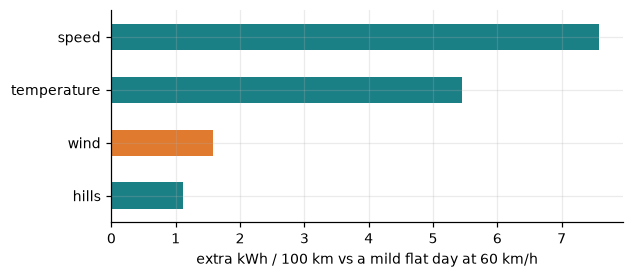

In [14]:
def cost(speed=30, temp=18, head=0, climb=0, descent=0):
    return model.predict(speed, temp, (speed + head) ** 2, climb, descent)


reference = cost()
effects = pd.Series(
    {
        "temperature": cost(temp=0) - reference,  # a freezing day
        "speed": cost(speed=110) - reference,  # motorway instead of country road
        "wind": cost(head=20) - reference,  # a 20 km/h headwind
        "hills": cost(climb=300, descent=300) - reference,  # 300 m up and down per 100 km
    }
).sort_values()
colours = ["#e07a2e" if k == MY_GUESS else "#1b7f86" for k in effects.index]
ax = effects.plot.barh(figsize=(6, 2.5), color=colours)
ax.set_xlabel("extra kWh / 100 km vs a mild flat day at 60 km/h")
print(f"your guess: {MY_GUESS} (orange) — biggest by the model: {effects.idxmax()}")

## What would make it better

* **More drives, in more weather.** Every coefficient tightens as winter arrives; the pull toward the specs
  then fades by itself, because the backtest stops rewarding it.
* **Cabin settings.** The car reports climate mode, set temperature and seat heating, but not the heater's
  power: a candidate feature once there are enough cold drives to tell them apart.
* **Route comparison.** The same model applied stretch by stretch to a planned route with forecast weather:
  the next step of the project.